# CENG 463 – HW3: CIFAR-10 Image Clustering
**Due Date:** 05.01.2026

As an **image clustering task**, you will work with the CIFAR-10 dataset, which contains images from 10 classes, including airplanes, cars, cats, and dogs. The goal is to use **unsupervised learning** techniques to group similar images automatically and visualize the results.

## 1. Dataset Overview (10 pts)
- Load the dataset using Keras (More information: [Keras CIFAR-10.](https://keras.io/api/datasets/cifar10/)):

    from keras.datasets import cifar10

   (x_train, y_train), (x_test, y_test) = cifar10.load_data()

- Show the dataset size and class names in a table.
- Display sample images from each class.


2025-12-27 11:46:07.877800: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/mmertince/Documents/GitHub/CENG463_HW_IMG_CLUSTERING/.venv/lib64/python3.13/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):
/home/mmertince/Documents/GitHub/CENG463_HW_IMG_CLUSTERING/.venv/lib64/python3.13/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")



------------------------------------------------------------
CIFAR-10 Dataset Summary
------------------------------------------------------------

Training set shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Test set shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)

------------------------------
 Dataset  Num Samples Image Shape  Num Classes
Training        50000     32×32×3           10
    Test        10000     32×32×3           10
   Total        60000     32×32×3           10

------------------------------------------------------------
Class Names
------------------------------------------------------------
 Class Index Class Name
           0   Airplane
           1 Automobile
           2       Bird
           3        Cat
           4       Deer
           5        Dog
           6       Frog
           7      Horse
           8       Ship
           9      Truck


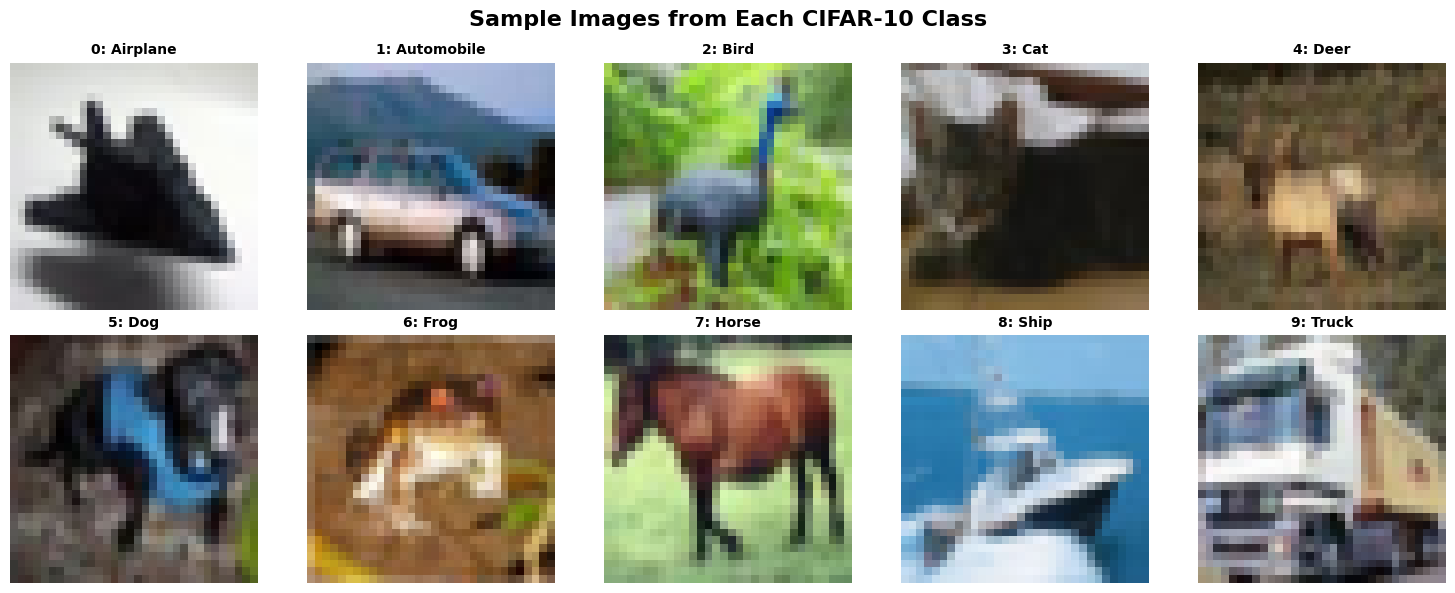


------------------------------------------------------------
Dataset loaded successfully!


In [2]:
#Dataset Overview

import keras
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#loading the dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

#CIFAR-10 dataset class names
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer', 'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

#displaying dataset size 
print("\n" + "-" * 60)
print("CIFAR-10 Dataset Summary")
print("-" * 60)
print(f"\nTraining set shape: {x_train.shape}")
print(f"Training labels shape: {y_train.shape}")
print(f"Test set shape: {x_test.shape}")
print(f"Test labels shape: {y_test.shape}")

#pandas dataframe for dataset summary
dataset_summary = pd.DataFrame({
    'Dataset': ['Training', 'Test', 'Total'],
    'Num Samples': [len(x_train), len(x_test), len(x_train) + len(x_test)],
    'Image Shape': ['32×32×3', '32×32×3', '32×32×3'], #32x32 images with 3 color channels(RGB)
    'Num Classes': [10, 10, 10]
})

print("\n" +"-" * 30)
print(dataset_summary.to_string(index=False))

#displaying class names

#pandas dataframe for class names
class_table = pd.DataFrame({
    'Class Index': range(10),
    'Class Name': class_names
})

print("\n" + "-" * 60)
print("Class Names")
print("-" * 60)
print(class_table.to_string(index=False))

#displayin sample images from each class
fig, axes = plt.subplots(2, 5, figsize=(15, 6)) #2 rows, 5 columns
fig.suptitle('Sample Images from Each CIFAR-10 Class', fontsize=16, fontweight='bold')

first_img_per_class = []

for i in range(10):
    #finding an image from each class
    class_i_samples = np.where(y_train == i)[0] #class i samples for class i(0 -> 'Airplane', 1 -> 'Automobile', ...)
    sample_idx = class_i_samples[0] #taking the first image from the class
    first_img_per_class.append(x_train[sample_idx])
    
    ax = axes[i // 5, i % 5] #positioning the subplot
    ax.imshow(first_img_per_class[i]) #displaying the image
    ax.set_title(f'{i}: {class_names[i]}', fontsize=10, fontweight='bold') #setting title
    ax.axis('off') #turning off axis

plt.tight_layout()
plt.show()

print("\n"  +"-" * 60)
print("Dataset loaded successfully!")

## 2. Feature Extraction and PCA (30 pts)
- Convert each image from 32×32×3 into a 3072-dimensional vector.
- Scale the vectors using StandardScaler.
- Apply PCA to reduce the dimensionality from 3072 → 50.

In [3]:
#Feature Extraction and PCA 

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#converting each image from 32×32×3 into a 3072-dimensional vector.
flattened_images = x_train.reshape(x_train.shape[0], -1)

#printing the shape of the converted vectors
print("\n" + "-" * 60)
print(f"Each image converted to vector of shape: {flattened_images[0].shape[0]}")
print("-" * 60)

#scale the vectors using StandardScaler
scaler = StandardScaler() #initializing the scaler
scaled_images = scaler.fit_transform(flattened_images.reshape(-1, 3072))
print("\n" + "-" * 60) 
print (f"Scaled image vectors shape: {scaled_images[0].shape[0]}")
print("-" * 60)

#apply PCA to reduce the dimensionality from 3072 to 50

pca = PCA(n_components=50)
pca.fit(scaled_images)
pca_images = pca.transform(scaled_images)


print("\n" + "-" * 60) 
print(f"Dimensionality reduced to: {pca_images.shape[1]} using PCA")
print("-" * 60)




------------------------------------------------------------
Each image converted to vector of shape: 3072
------------------------------------------------------------

------------------------------------------------------------
Scaled image vectors shape: 3072
------------------------------------------------------------

------------------------------------------------------------
Dimensionality reduced to: 50 using PCA
------------------------------------------------------------


## 3. Clustering Methods (30 pts)
- Perform clustering on the PCA-transformed features using three Sklearn algorithms: K-Means, Agglomerative Clustering, DBSCAN.
- Visualize example images for each cluster.
- Provide short comments on the clusters.

10000
50000

------------------------------------------------------------
Performing Clustering with K-Means Algorithm..
------------------------------
Number of clusters found with K-Means: 10
------------------------------------------------------------

------------------------------------------------------------
Performing Clustering with Agglomerative Clustering Algorithm..
------------------------------
Number of clusters found with Agglomerative Clustering: 10
------------------------------------------------------------

------------------------------------------------------------
Performing Clustering with DBSCAN Algorithm..
------------------------------
Number of clusters found with DBSCAN: 4
------------------------------------------------------------


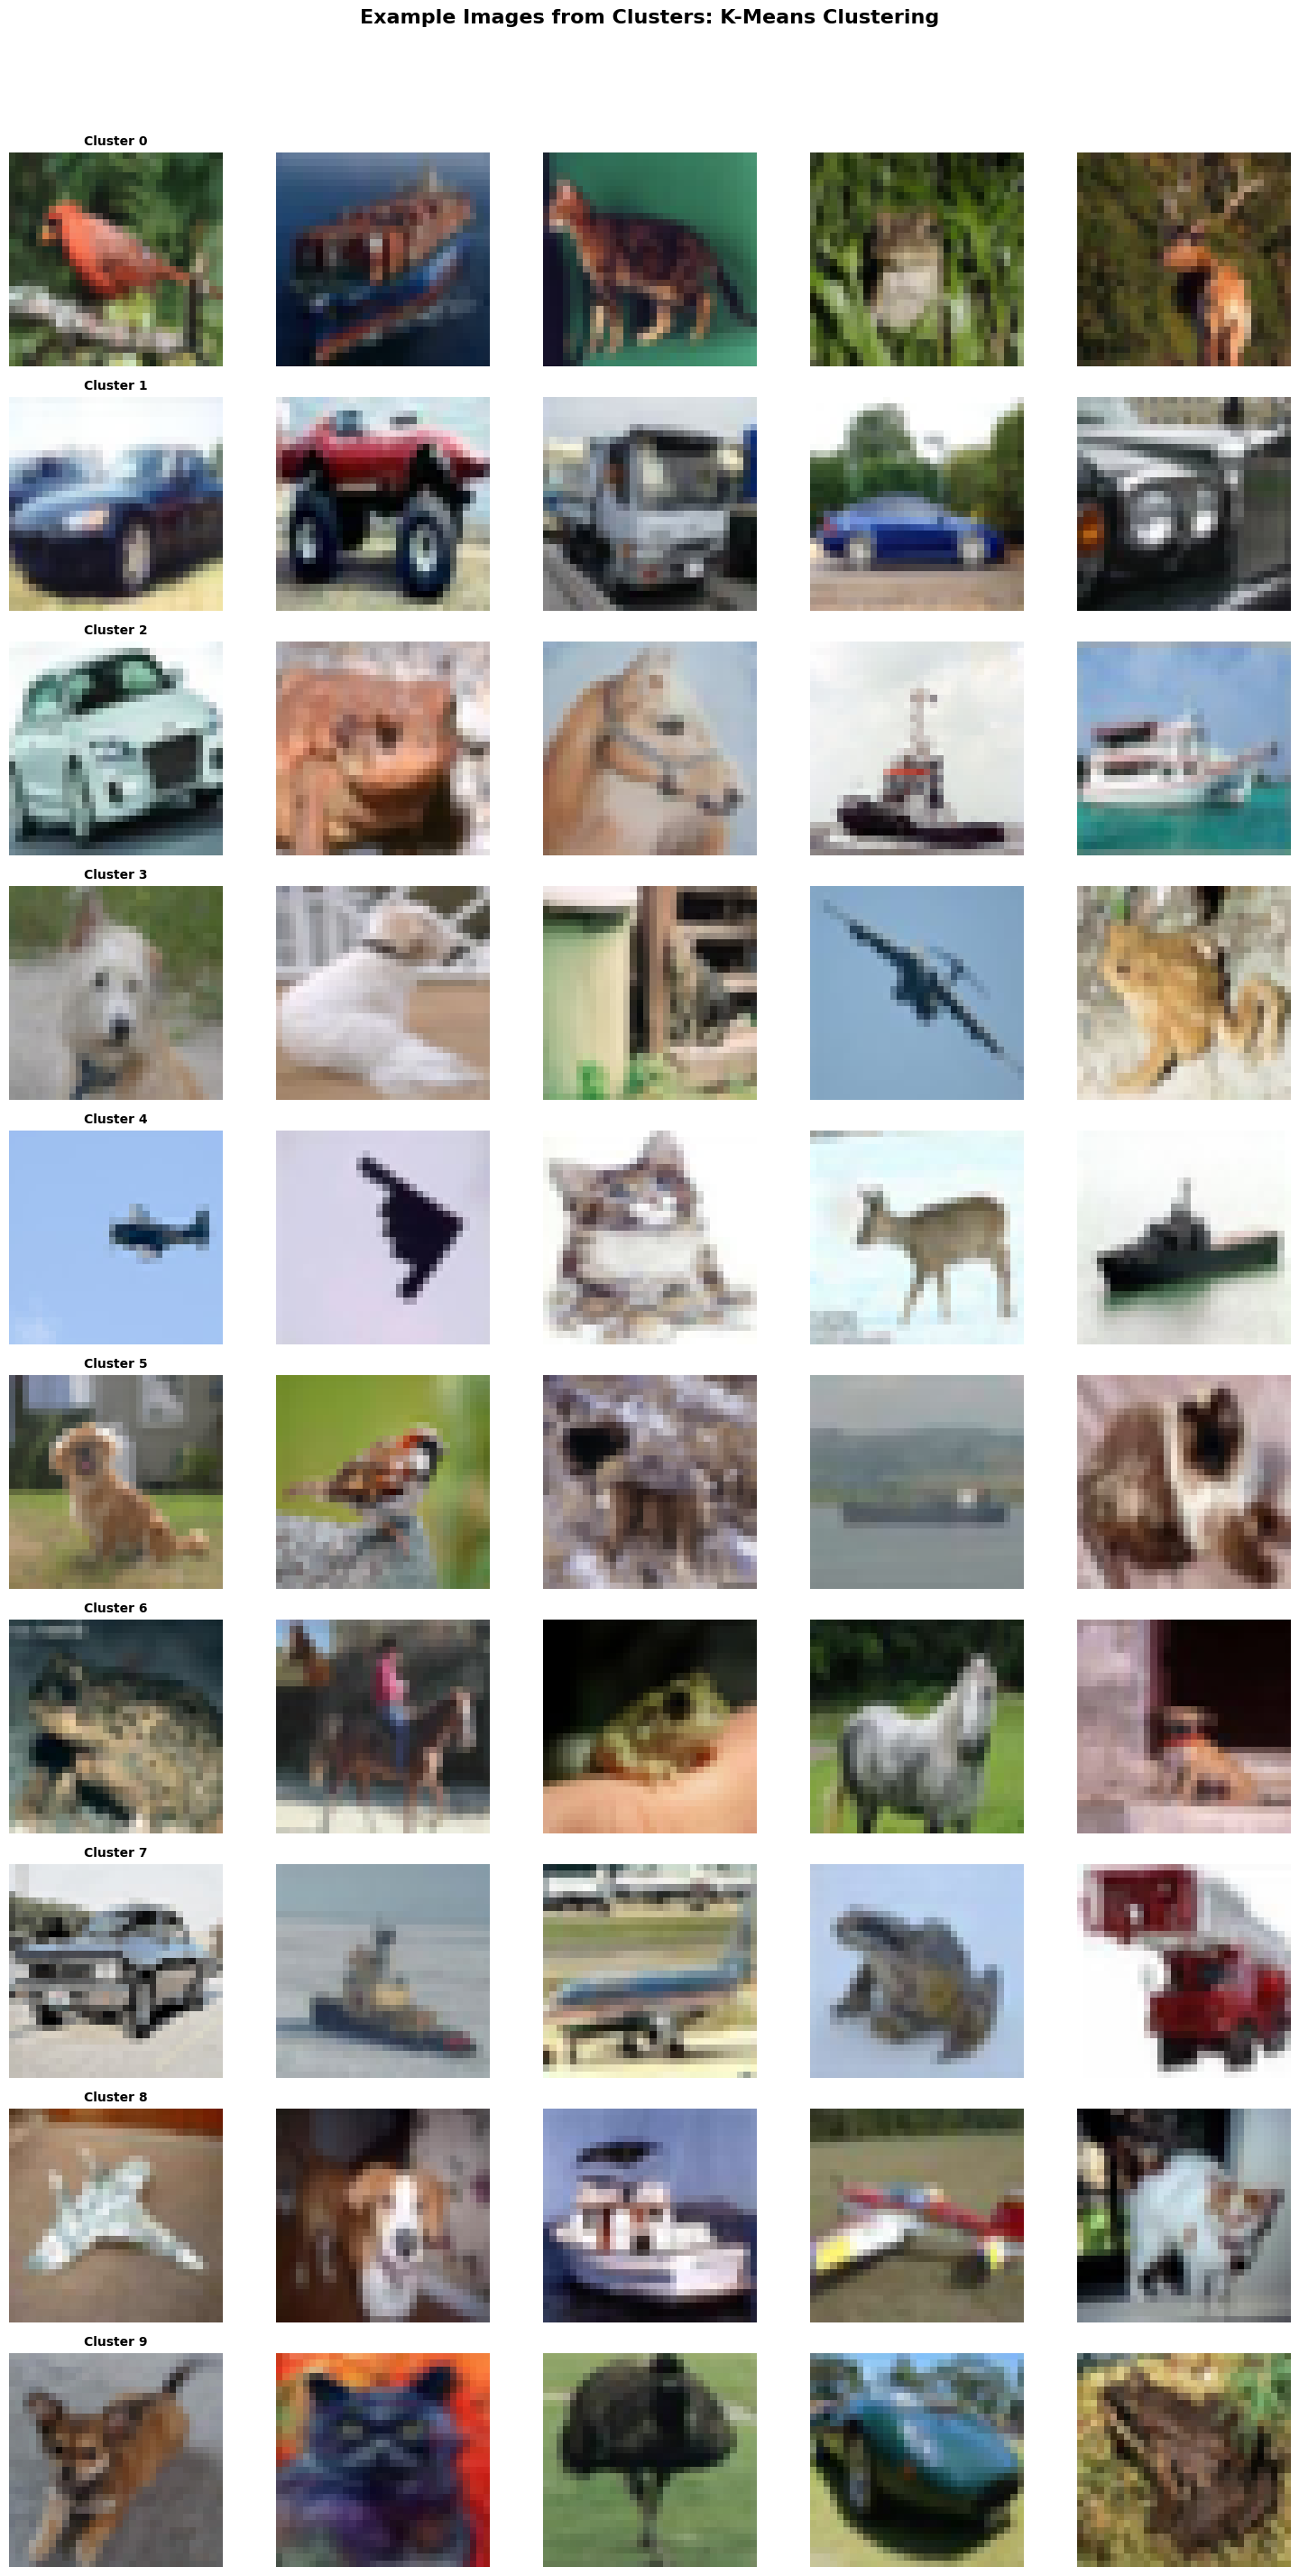

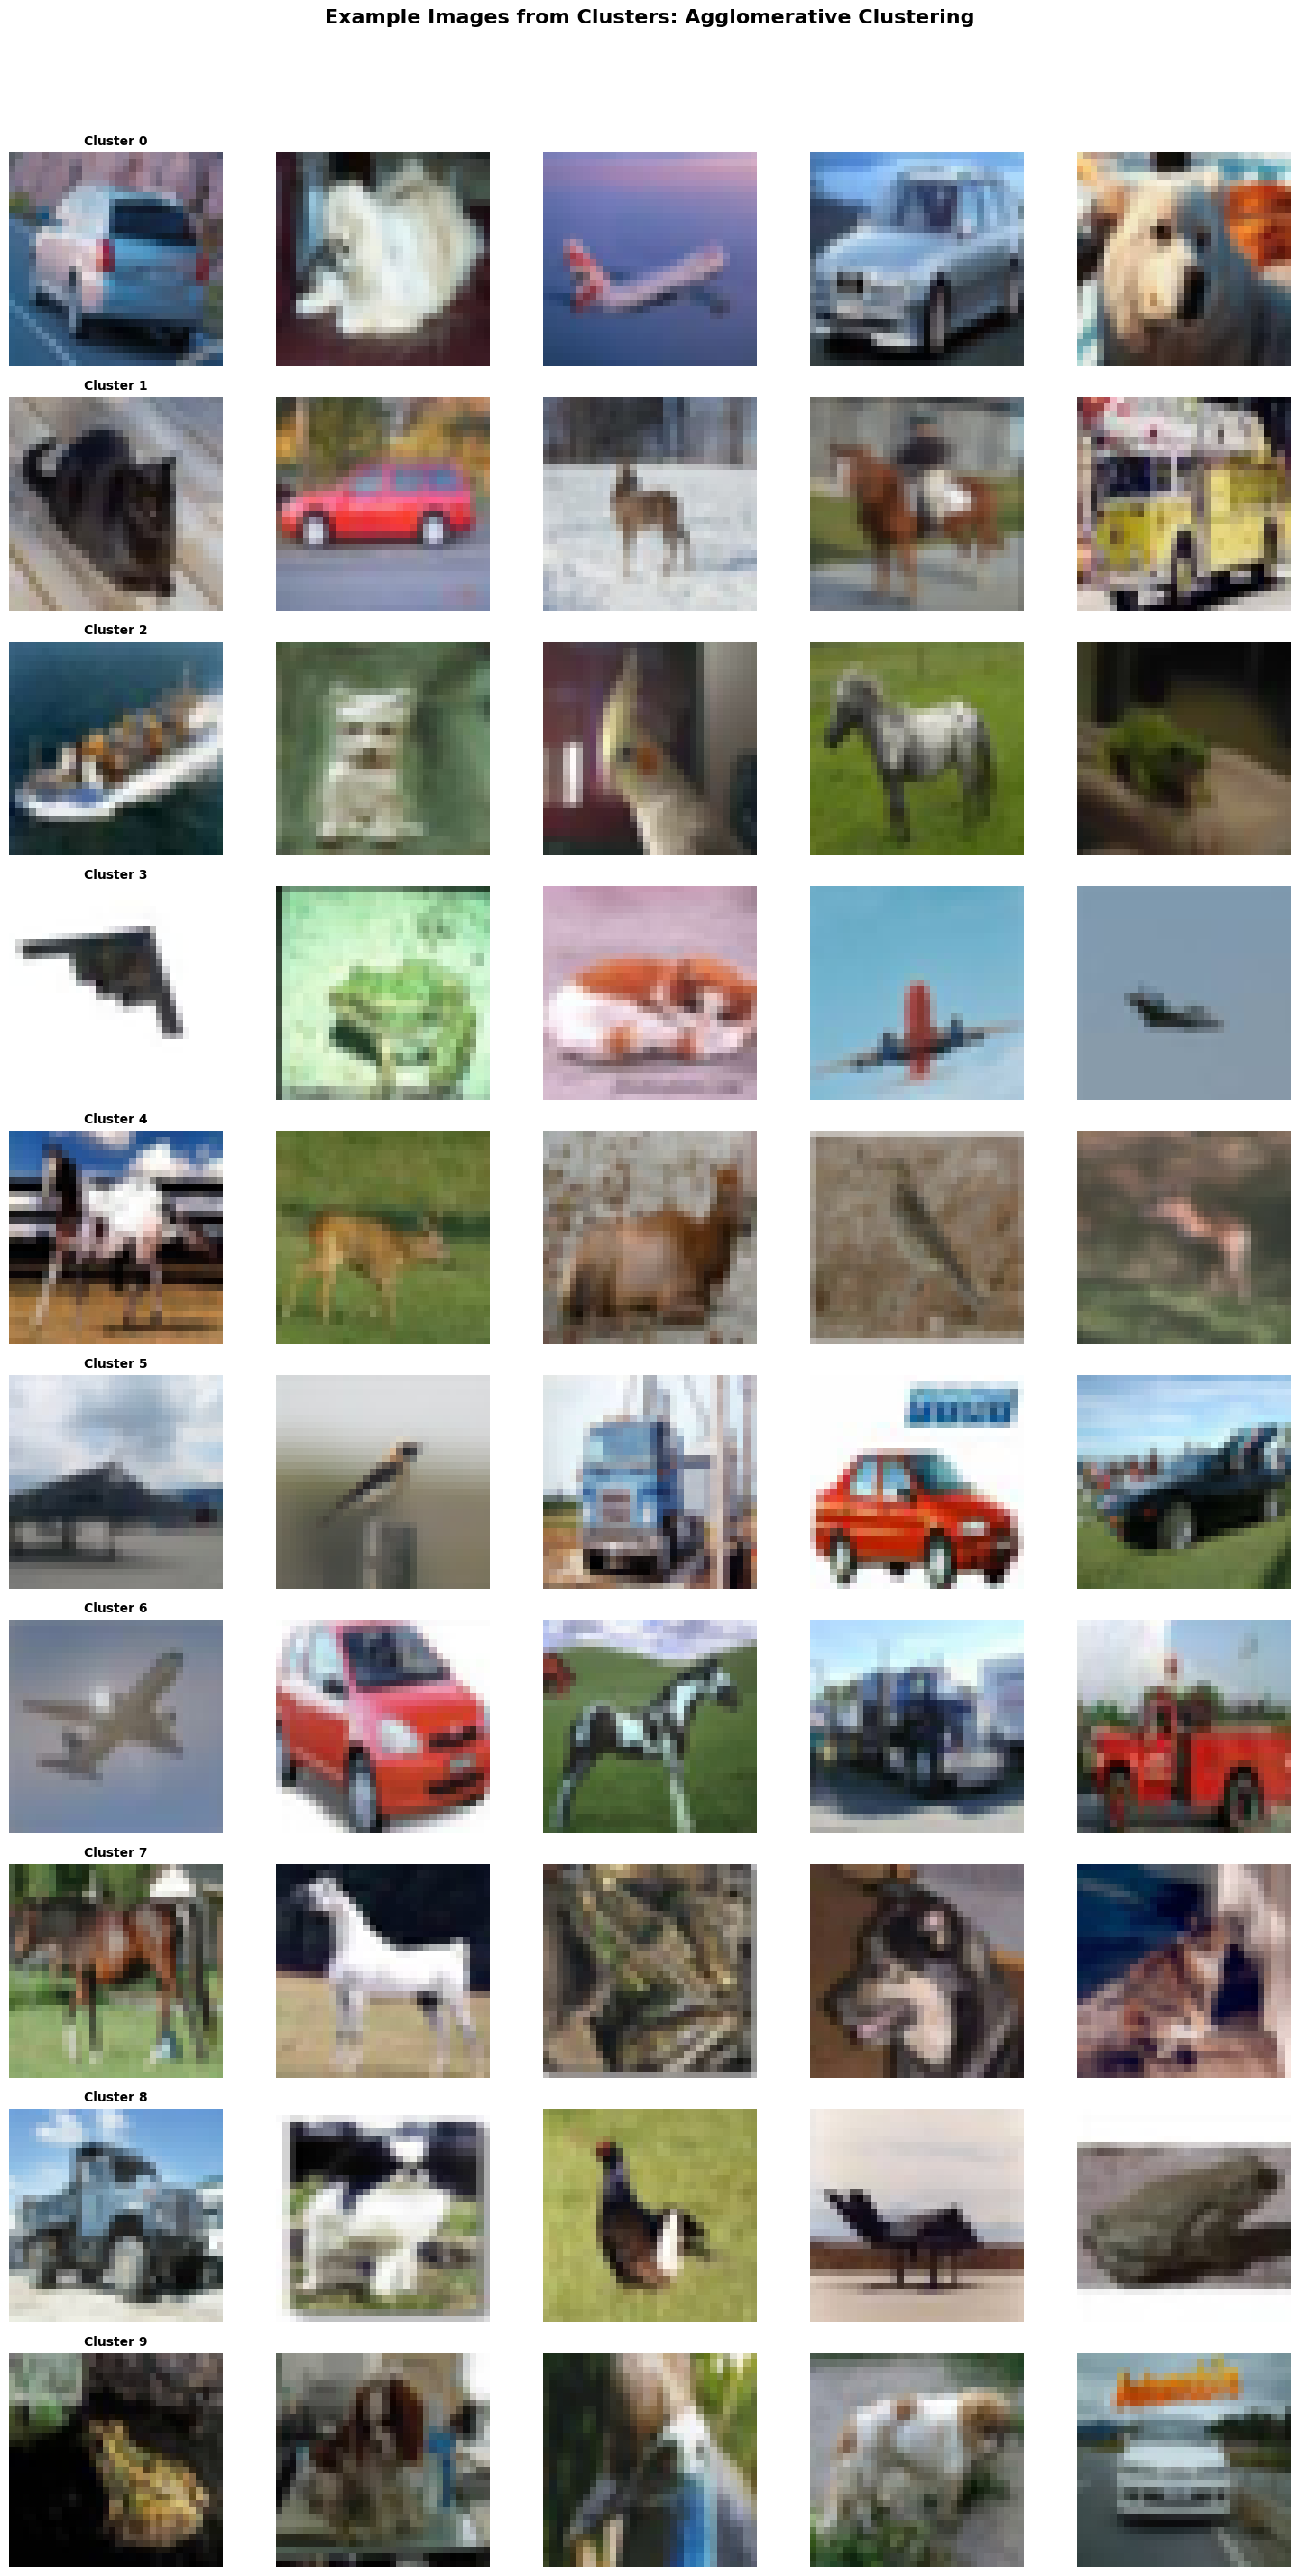

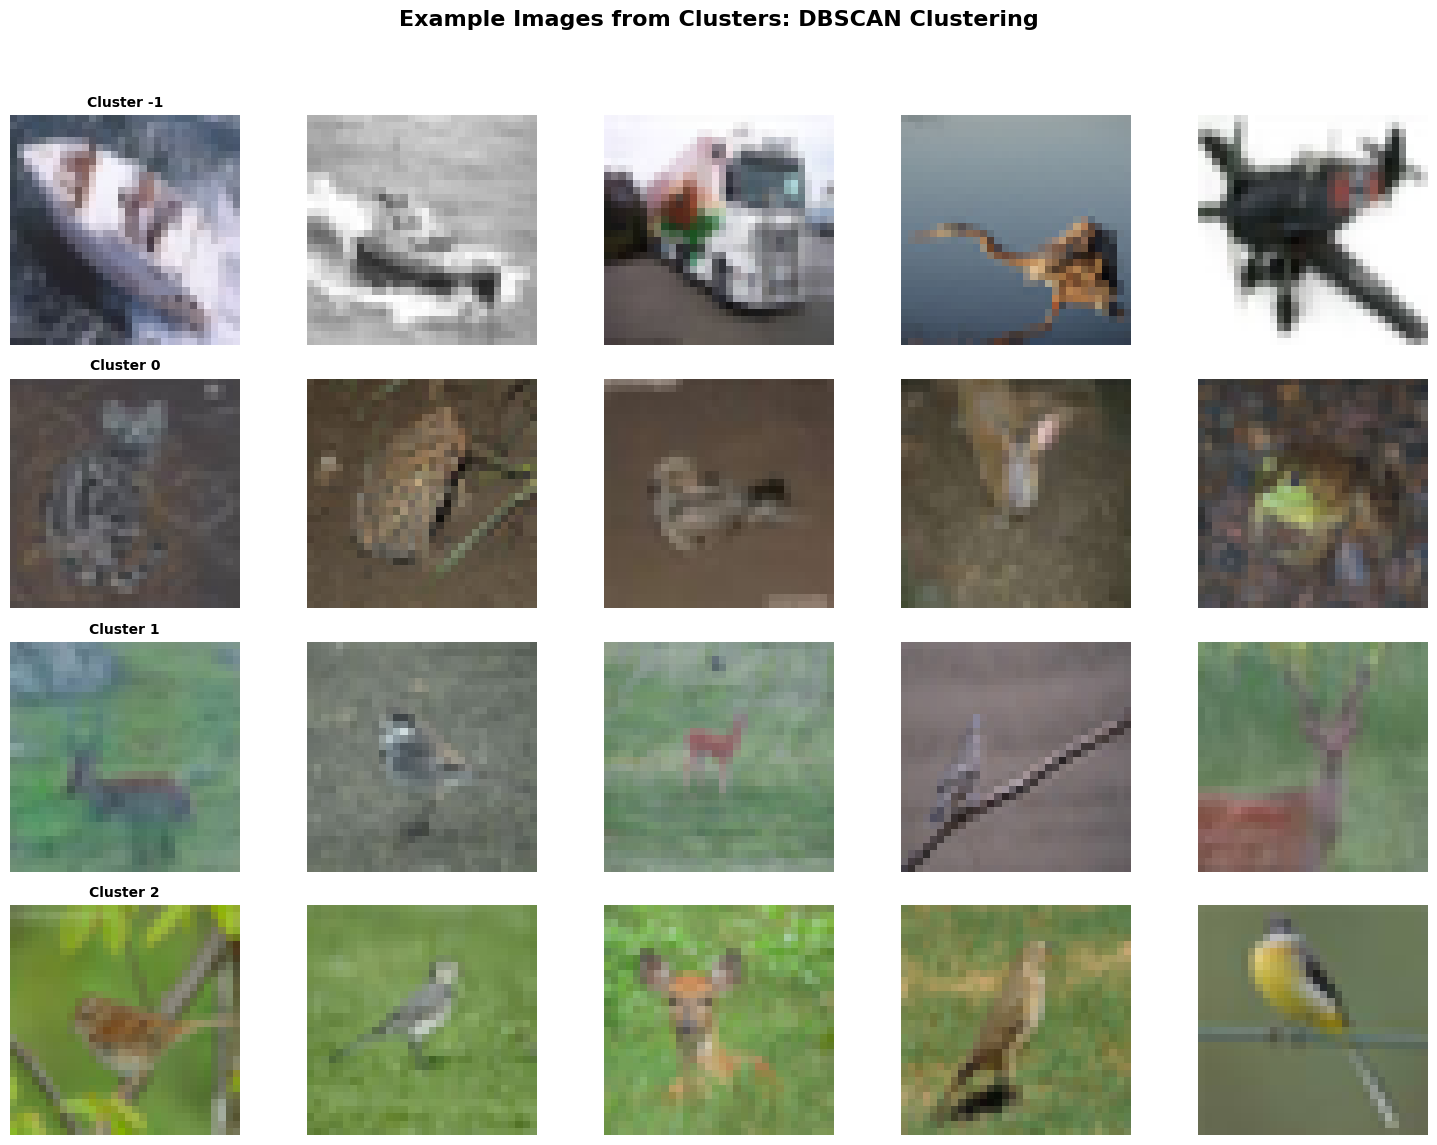

In [17]:
#TO-DO: - Provide short comments on the clusters.

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

#- Perform clustering on the PCA-transformed features using three Sklearn algorithms: K-Means, Agglomerative Clustering, DBSCAN.

#to not to get a memory shortage, keep the runtime reasonable, cluster on a subset
rng = np.random.default_rng(42)
sample_size = min(10000, len(pca_images))
sample_idx = rng.choice(len(pca_images), size=sample_size, replace=False)
X_cluster = pca_images[sample_idx]
X_images = x_train[sample_idx]  #for visualization
print(len(X_cluster))
print(len(pca_images))

#Perform clustering on the PCA-transformed features using K-Means
print("\n" + "-" * 60) 
print(f"Performing Clustering with K-Means Algorithm..")
kmeans = KMeans(n_clusters=10, random_state=42) 
kmeans.fit(X_cluster) #fit pca reduced images to kmeans
print("-" * 30)
print(f"Number of clusters found with K-Means: {len(np.unique(kmeans.labels_))}")
print("-" * 60)

#Perform clustering on the PCA-transformed features using Agglomerative Clustering
print("\n" + "-" * 60) 
print(f"Performing Clustering with Agglomerative Clustering Algorithm..")
agg_clust = AgglomerativeClustering(n_clusters=10) 
agg_clust = agg_clust.fit(X_cluster) #fit pca reduced images to agglomer
print("-" * 30)
print(f"Number of clusters found with Agglomerative Clustering: {len(np.unique(agg_clust.labels_))}")
print("-" * 60)

#Perform clustering on the PCA-transformed features using DBSCAN
print("\n" + "-" * 60) 
print(f"Performing Clustering with DBSCAN Algorithm..")
dbscan = DBSCAN(eps=15, min_samples=5, metric='euclidean') 
dbscan = dbscan.fit(X_cluster) #fit pca reduced images to dbscan
print("-" * 30)
print(f"Number of clusters found with DBSCAN: {len(np.unique(dbscan.labels_))}")
print("-" * 60)


#- Visualize example images for each cluster.
def visualize_clusters(images, labels, title, samples_per_cluster=5, max_clusters=10):
    unique_labels = np.unique(labels)
    n_clusters = min(len(unique_labels), max_clusters)
    
    plt.figure(figsize=(15, n_clusters * 3))
    plt.suptitle(f'Example Images from Clusters: {title}', fontsize=16, fontweight='bold')
    
    for i, label in enumerate(unique_labels[:max_clusters]):
        cluster_indices = np.where(labels == label)[0]
        selected_indices = np.random.choice(cluster_indices, size=min(samples_per_cluster, len(cluster_indices)), replace=False)
        
        for j, idx in enumerate(selected_indices):
            plt.subplot(n_clusters, samples_per_cluster, i * samples_per_cluster + j + 1)
            plt.imshow(images[idx])
            plt.axis('off')
            if j == 0:
                plt.title(f'Cluster {label}', fontsize=10, fontweight='bold')
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

visualize_clusters(X_images, kmeans.labels_, title='K-Means Clustering')
visualize_clusters(X_images, agg_clust.labels_, title='Agglomerative Clustering')
visualize_clusters(X_images, dbscan.labels_, title='DBSCAN Clustering')



## 4. Visualization and Analysis (30 pts)
- Use t-SNE to reduce PCA features to 2D for visualization.
- Create colored scatter plots for each clustering algorithm.
- Observe which classes are better grouped by each algorithm.


------------------------------------------------------------
Applying t-SNE to reduce dimensions from 50D to 2D...
------------------------------------------------------------

------------------------------------------------------------
t-SNE reduction complete. New shape: (10000, 2)
------------------------------------------------------------


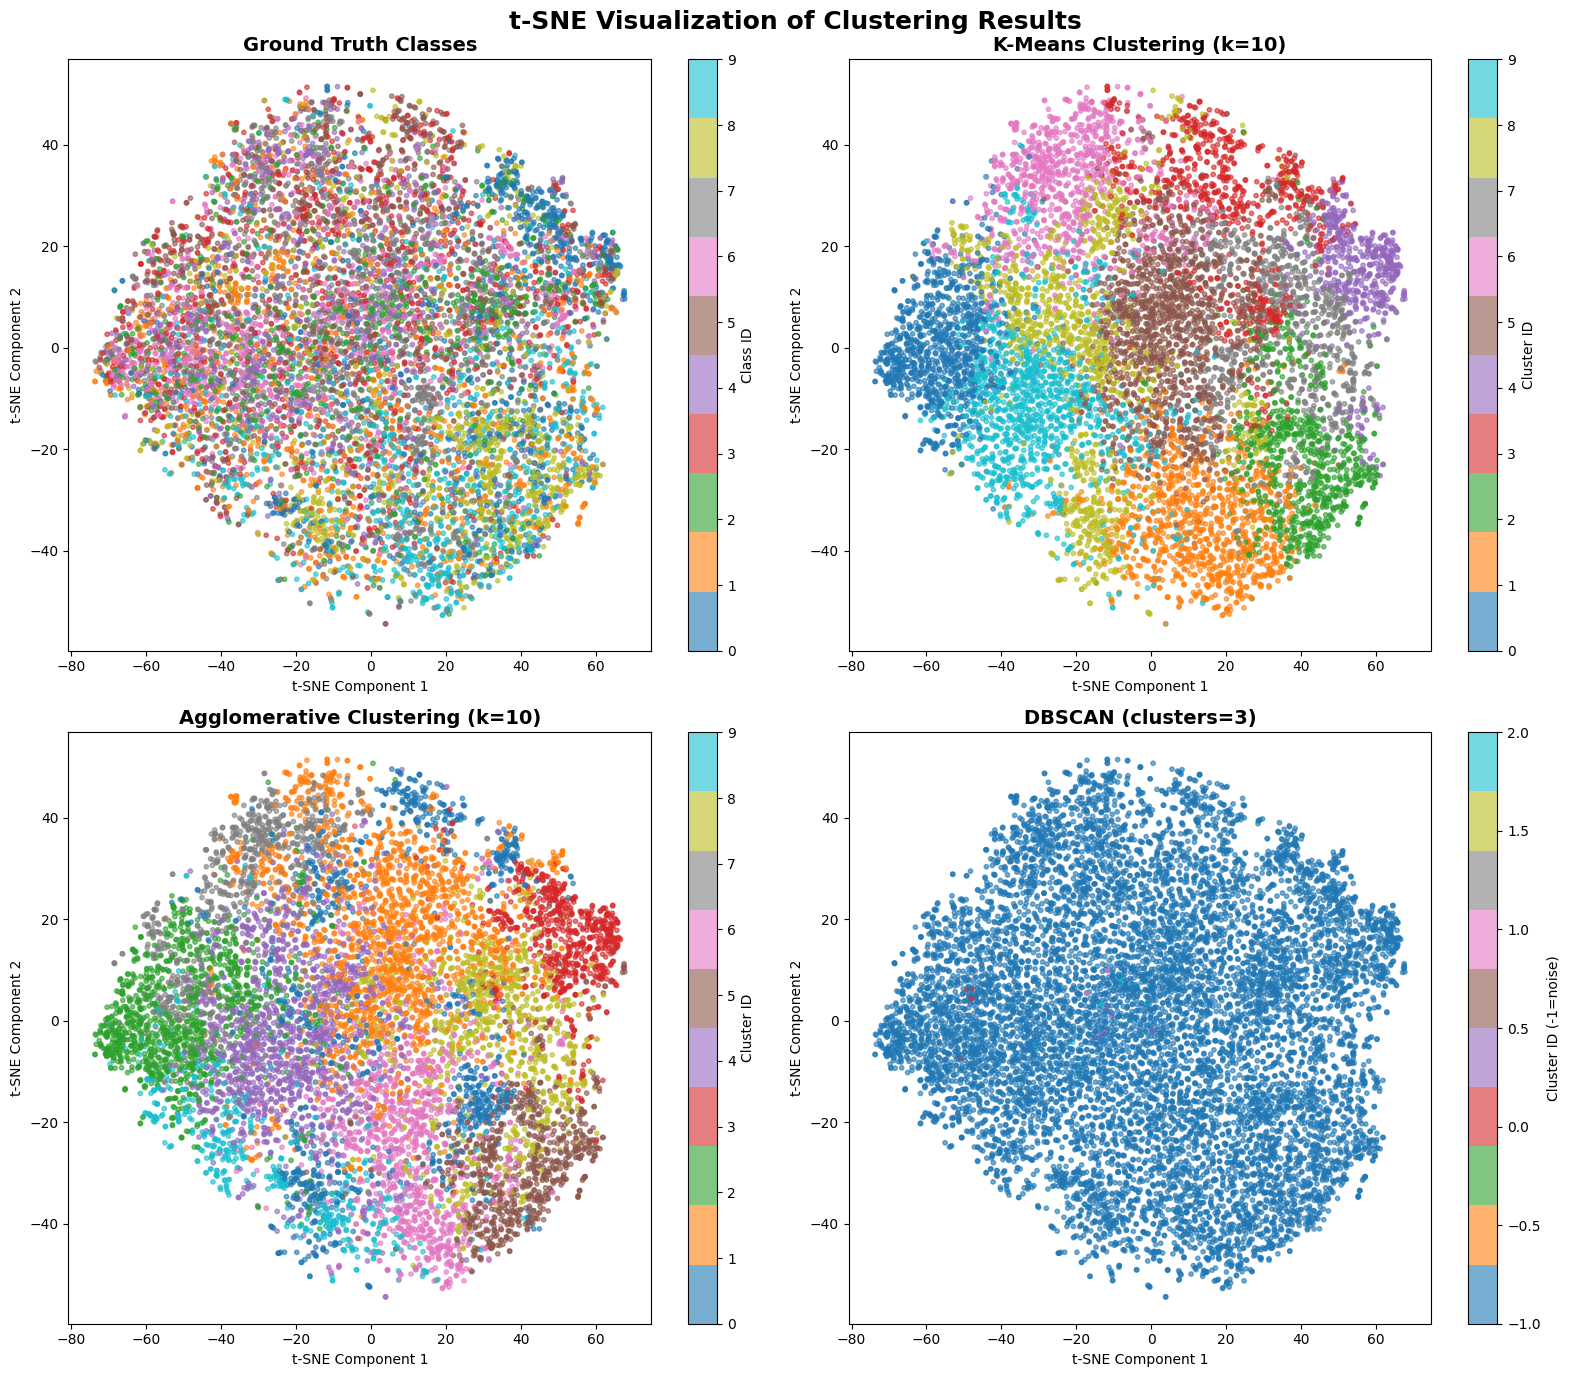


------------------------------------------------------------
OBSERVATIONS AND ANALYSIS
------------------------------------------------------------


In [ ]:
# Visualization and Analysis using t-SNE

from sklearn.manifold import TSNE

#- Use t-SNE to reduce PCA features to 2D for visualization.

print("\n" + "-" * 60)
print("Applying t-SNE to reduce dimensions from 50D to 2D...")
print("-" * 60)

tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_cluster) 

print("\n" + "-" * 60)
print(f"t-SNE reduction complete. New shape: {X_tsne.shape}")
print("-" * 60)

#get the ids of discrete classes for the sampled data
y_sampled = y_train[sample_idx].flatten()


#- Create colored scatter plots for each clustering algorithm.
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.suptitle('t-SNE Visualization of Clustering Results', fontsize=18, fontweight='bold')

#plot 1: ground truth
ax1 = axes[0, 0]
scatter1 = ax1.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_sampled, cmap='tab10', s=10, alpha=0.6)
ax1.set_title('Ground Truth Classes', fontsize=14, fontweight='bold')
ax1.set_xlabel('t-SNE Component 1')
ax1.set_ylabel('t-SNE Component 2')
cbar1 = plt.colorbar(scatter1, ax=ax1)
cbar1.set_label('Class ID')

#plot 2: K-Means clustering
ax2 = axes[0, 1]
scatter2 = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans.labels_, cmap='tab10', s=10, alpha=0.6)
ax2.set_title(f'K-Means Clustering (k={len(np.unique(kmeans.labels_))})', fontsize=14, fontweight='bold')
ax2.set_xlabel('t-SNE Component 1')
ax2.set_ylabel('t-SNE Component 2')
cbar2 = plt.colorbar(scatter2, ax=ax2)
cbar2.set_label('Cluster ID')

#plot 3: Agglomerative Clustering
ax3 = axes[1, 0]
scatter3 = ax3.scatter(X_tsne[:, 0], X_tsne[:, 1], c=agg_clust.labels_, cmap='tab10', s=10, alpha=0.6)
ax3.set_title(f'Agglomerative Clustering (k={len(np.unique(agg_clust.labels_))})', fontsize=14, fontweight='bold')
ax3.set_xlabel('t-SNE Component 1')
ax3.set_ylabel('t-SNE Component 2')
cbar3 = plt.colorbar(scatter3, ax=ax3)
cbar3.set_label('Cluster ID')

#plot 4: DBSCAN
ax4 = axes[1, 1]
scatter4 = ax4.scatter(X_tsne[:, 0], X_tsne[:, 1], c=dbscan.labels_, cmap='tab10', s=10, alpha=0.6)
ax4.set_title(f'DBSCAN (clusters={len(np.unique(dbscan.labels_[dbscan.labels_ != -1]))})', fontsize=14, fontweight='bold')
ax4.set_xlabel('t-SNE Component 1')
ax4.set_ylabel('t-SNE Component 2')
cbar4 = plt.colorbar(scatter4, ax=ax4)
cbar4.set_label('Cluster ID (-1=noise)')

plt.tight_layout()
plt.show()


#- Observe which classes are better grouped by each algorithm.
print("\n" + "-" * 60)
print("OBSERVATIONS AND ANALYSIS")
print("-" * 60)

#TO-DO:Observe which classes are better grouped by each algorithm.

